In [45]:
# LAB EXPERIMENT 1
# LINEAR REGRESSION AND REGULARIZATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [47]:
# 1. LOAD CALIFORNIA HOUSING DATASET


data = fetch_california_housing()

X = data.data
y = data.target

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

#convert into dataframe

df = pd.DataFrame(X, columns=data.feature_names)

df["Target"] = y

print(df.head())


Shape of X: (20640, 8)
Shape of y: (20640,)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Target  
0    -122.23   4.526  
1    -122.22   3.585  
2    -122.24   3.521  
3    -122.25   3.413  
4    -122.25   3.422  


In [48]:
# 4 . Check Dataset Information


print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print(df.info())

Number of rows: 20640
Number of columns: 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


In [50]:
#5.Split Data into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# 6.Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#7. Linear Regression using Normal Equation
class LinearRegressionNormalEquation:

    def __init__(self):
        self.weights = None
        self.bias = None

    def fit(self, X, y):

        # Add column of ones for bias
        X_b = np.c_[np.ones((X.shape[0], 1)), X]

        # Normal Equation
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y

        self.bias = theta[0]
        self.weights = theta[1:]

    def predict(self, X):

        return np.dot(X, self.weights) + self.bias

Training data: (16512, 8)
Testing data: (4128, 8)


In [51]:
# 5. TRAIN NORMAL EQUATION MODEL

normal_model = LinearRegressionNormalEquation()

normal_model.fit(X_train_scaled, y_train)

y_pred_normal = normal_model.predict(X_test_scaled)

In [52]:
# 6. LINEAR REGRESSION FROM SCRATCH
#    USING GRADIENT DESCENT

class LinearRegressionGradientDescent:

    def __init__(self, learning_rate=0.01, epochs=1000):

        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = 0

        self.loss_history = []

    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialize weights
        self.weights = np.zeros(n_features)

        # Initialize bias
        self.bias = 0

        # Gradient Descent
        for epoch in range(self.epochs):

            # Prediction
            y_pred = np.dot(X, self.weights) + self.bias

            # Error
            error = y_pred - y

            # Mean Squared Error
            loss = np.mean(error ** 2)

            # Store loss
            self.loss_history.append(loss)

            # Calculate gradients
            dw = (2 / n_samples) * np.dot(X.T, error)

            db = (2 / n_samples) * np.sum(error)

            # Update weights
            self.weights -= self.learning_rate * dw

            # Update bias
            self.bias -= self.learning_rate * db

    def predict(self, X):

        return np.dot(X, self.weights) + self.bias

In [54]:
    # Training
    
gd_model = LinearRegressionGradientDescent(
    learning_rate=0.01,
    epochs=1000
)

gd_model.fit(X_train_scaled, y_train)

y_pred_gd = gd_model.predict(X_test_scaled)

#check loss value

print("Number of epochs:", gd_model.epochs)

print("Number of loss values:", len(gd_model.loss_history))

Number of epochs: 1000
Number of loss values: 1000


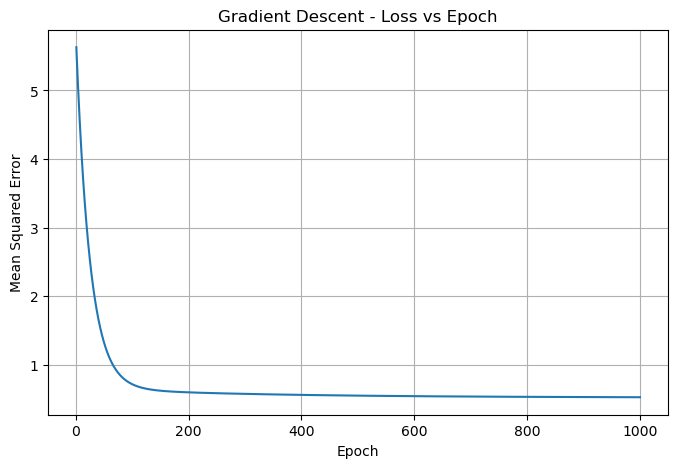

In [55]:
# 7.  GRADIENT DESCENT graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, gd_model.epochs + 1),
    gd_model.loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.title("Gradient Descent - Loss vs Epoch")

plt.grid(True)

plt.show()

In [56]:
#13. Linear Regression using Scikit-Learn
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)




In [57]:
# 14. RIDGE REGRESSION


ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)

In [58]:
# 15. LASSO REGRESSION

lasso_model = Lasso(alpha=0.01)

lasso_model.fit(X_train_scaled, y_train)

y_pred_lasso = lasso_model.predict(X_test_scaled)

In [59]:
#16. Calculate MSE and R²

print("Normal Equation")
print("MSE:", mean_squared_error(y_test, y_pred_normal))
print("R2 Score:", r2_score(y_test, y_pred_normal))

print("\nGradient Descent")
print("MSE:", mean_squared_error(y_test, y_pred_gd))
print("R2 Score:", r2_score(y_test, y_pred_gd))

print("\nScikit-Learn Linear Regression")
print("MSE:", mean_squared_error(y_test, y_pred_linear))
print("R2 Score:", r2_score(y_test, y_pred_linear))

print("\nRidge Regression")
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("R2 Score:", r2_score(y_test, y_pred_ridge))

print("\nLasso Regression")
print("MSE:", mean_squared_error(y_test, y_pred_lasso))
print("R2 Score:", r2_score(y_test, y_pred_lasso))

Normal Equation
MSE: 0.5558915986952424
R2 Score: 0.5757877060324523

Gradient Descent
MSE: 0.5545795065308549
R2 Score: 0.5767889905063643

Scikit-Learn Linear Regression
MSE: 0.5558915986952443
R2 Score: 0.5757877060324508

Ridge Regression
MSE: 0.5558548589435974
R2 Score: 0.575815742891368

Lasso Regression
MSE: 0.5482548967938964
R2 Score: 0.5816154300698727


In [60]:
# 17. Actual vs Predicted Values

comparison = pd.DataFrame({
    "Actual": y_test[:20],
    "Normal Equation": y_pred_normal[:20],
    "Gradient Descent": y_pred_gd[:20],
    "Linear Regression": y_pred_linear[:20],
    "Ridge": y_pred_ridge[:20],
    "Lasso": y_pred_lasso[:20]
})

print(comparison)



     Actual  Normal Equation  Gradient Descent  Linear Regression     Ridge  \
0   0.47700         0.719123          0.797952           0.719123  0.719472   
1   0.45800         1.764017          1.708565           1.764017  1.763847   
2   5.00001         2.709659          2.630398           2.709659  2.709309   
3   2.18600         2.838926          2.798757           2.838926  2.838757   
4   2.78000         2.604657          2.468767           2.604657  2.604177   
5   1.58700         2.011754          2.053983           2.011754  2.011905   
6   1.98200         2.645500          2.664443           2.645500  2.645536   
7   1.57500         2.168755          2.172797           2.168755  2.168761   
8   3.40000         2.740746          2.573576           2.740746  2.740130   
9   4.46600         3.915615          3.991586           3.915615  3.915749   
10  1.23200         0.938962          1.065495           0.938962  0.939451   
11  2.53900         1.901222          1.899844      

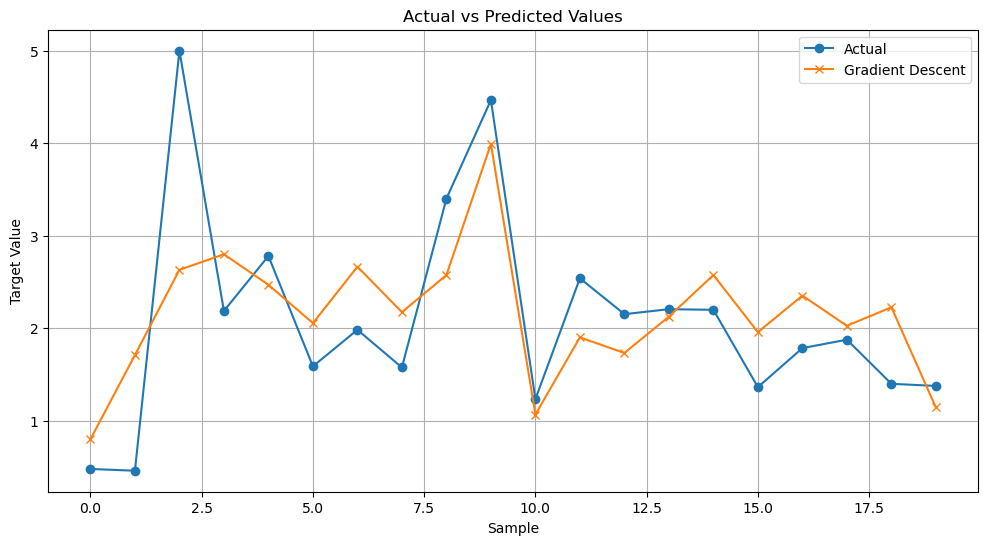

In [61]:
# 18. ACTUAL VS PREDICTED GRAPH

plt.figure(figsize=(12, 6))

plt.plot(
    range(20),
    y_test[:20],
    marker='o',
    label="Actual"
)

plt.plot(
    range(20),
    y_pred_gd[:20],
    marker='x',
    label="Gradient Descent"
)

plt.xlabel("Sample")
plt.ylabel("Target Value")

plt.title("Actual vs Predicted Values")

plt.legend()

plt.grid(True)

plt.show()

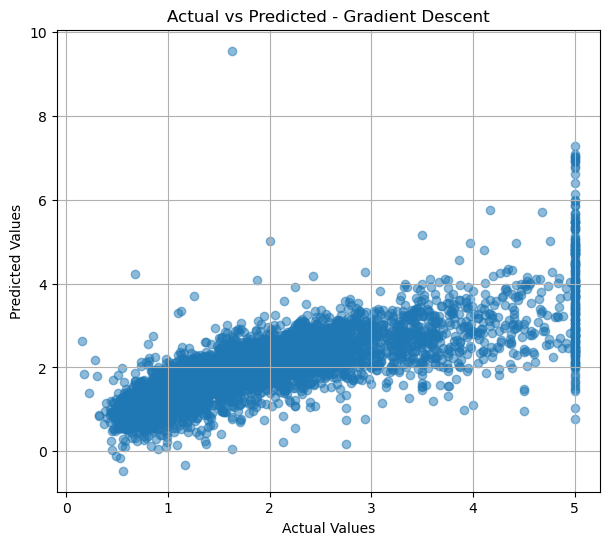

In [62]:
# 15. ACTUAL VS PREDICTED SCATTER PLOT
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred_gd,
    alpha=0.5
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted - Gradient Descent")

plt.grid(True)

plt.show()

In [65]:
# 20. Simple Regression Line using MedInc
X_simple = df[["MedInc"]]
y_simple = df["Target"]


#Split Simple Dataset
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)


#Train Simple Linear Regression
simple_model = LinearRegression()

simple_model.fit(
    X_train_simple,
    y_train_simple
)

y_pred_simple = simple_model.predict(X_test_simple)

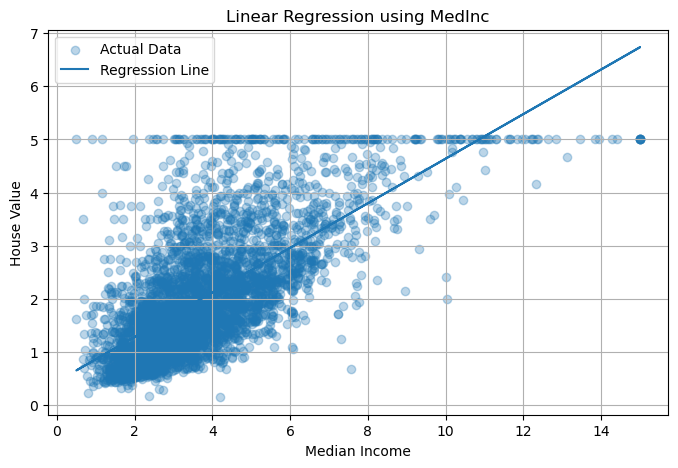

In [66]:
# 23. Plot Regression Line

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_simple,
    y_test_simple,
    alpha=0.3,
    label="Actual Data"
)

plt.plot(
    X_test_simple,
    y_pred_simple,
    label="Regression Line"
)

plt.xlabel("Median Income")

plt.ylabel("House Value")

plt.title("Linear Regression using MedInc")

plt.legend()

plt.grid(True)

plt.show()